In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [2]:
mask_metadata = pd.read_csv("../metadata/Recording_metadata.csv")
mask_metadata

,Brain,Recording,Stimulus,Mask,Plane,Region,Side,Imaging_FPS,Video_FPS,Feeding_start_time (s),Feeding_stop_time (s),Feeding_duration (s)
0,AKG_B30,R1,NHS60,5,1,gamma1pedc,Right,1.254170,15.0,217.066667,519.866667,302.800000
1,AKG_B30,R1,NHS60,2,1,gamma1pedc,Left,1.254170,15.0,217.066667,519.866667,302.800000
2,AKG_B31,R1,NHS60,2,0,gamma1pedc,Left,1.377122,15.0,218.533333,522.733333,304.200000
3,AKG_B31,R1,NHS60,3,1,gamma1pedc,Right,1.377088,15.0,218.533333,522.733333,304.200000
4,AKG_B32,R1,NHS60,2,0,gamma1pedc,Left,1.251235,15.0,222.266667,516.400000,294.133333
5,AKG_B32,R1,NHS60,3,1,gamma1pedc,Left,1.251212,15.0,222.266667,516.400000,294.133333
6,AKG_B32,R1,NHS60,6,1,gamma1pedc,Right,1.251212,15.0,222.266667,516.400000,294.133333
7,AKG_B33,R1,NHS60,6,0,gamma1pedc,Right,1.281426,15.0,233.600000,534.800000,301.200000
8,AKG_B33,R1,NHS60,2,0,gamma1pedc,Left,1.281426,15.0,233.600000,534.800000,301.200000
9,AKG_B34,R1,NHS60,2,0,gamma1pedc,Left,1.316616,15.0,218.866667,519.133333,300.266667


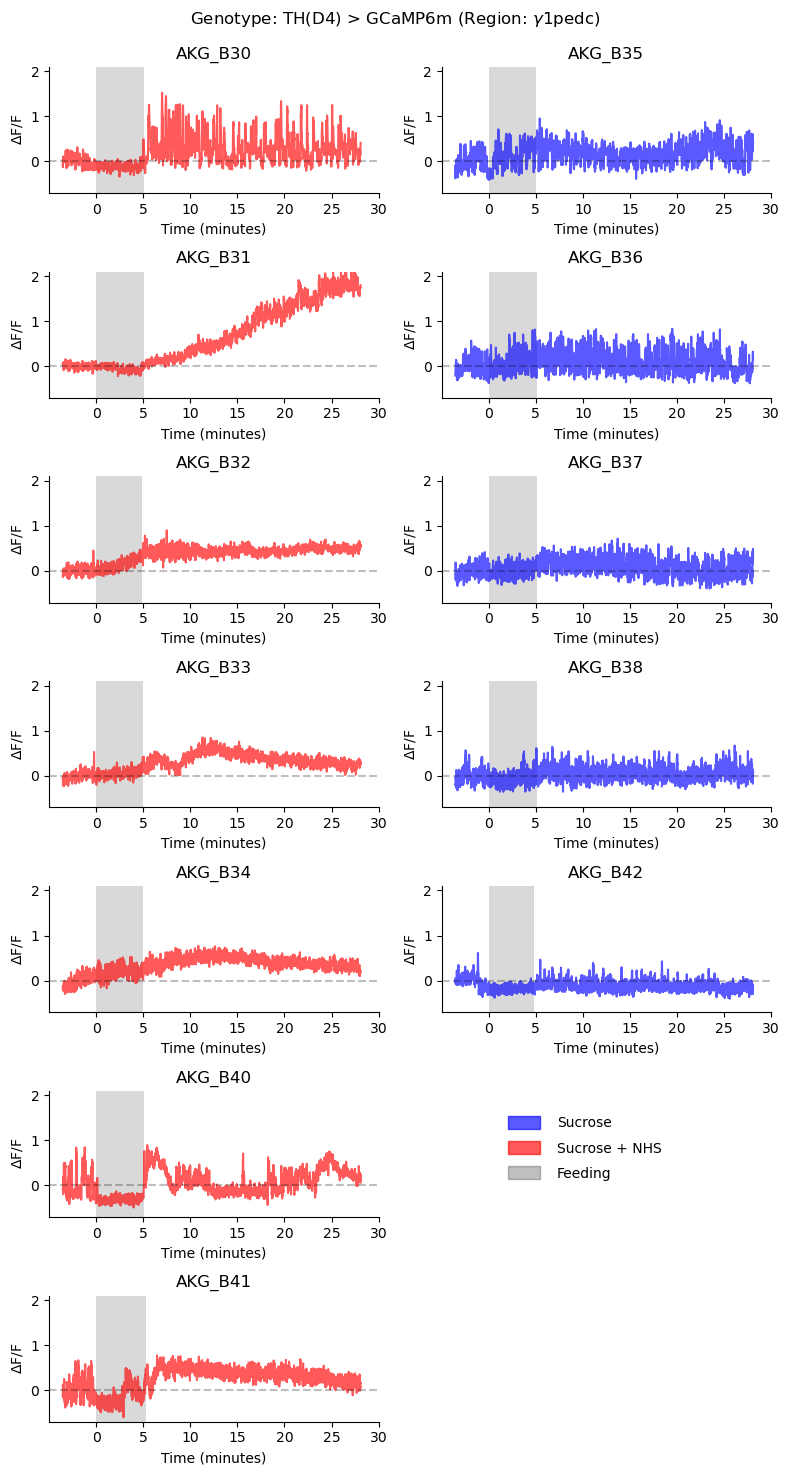

In [3]:
stimuli = mask_metadata["Stimulus"].unique()

region = "gamma1pedc"

ymin = -0.7
ymax = 2.1

fig,axs = plt.subplots(7,2,figsize=(8,15))

for stimulus in stimuli:

    df_data = pd.read_csv(f"../csv_files/Brainwise_aligned_dFF_traces_of_{region}_for_{stimulus}.csv",index_col=0)
    
    time = df_data.index/60000
    
    for c,col in enumerate(df_data.columns):
    
        if stimulus == "Sucrose":
            ax = axs[c,1]
            axs[5,1].axis("off")
            axs[6,1].axis("off")
            color = "blue"
                
        elif stimulus == "NHS60":
            ax = axs[c,0]
            color = "red"

        feeding_duration = mask_metadata[(mask_metadata["Region"] == region) & (mask_metadata["Stimulus"] == stimulus) & (mask_metadata["Brain"] == col)]["Feeding_duration (s)"].unique()[0]
        
        ax.plot(time, df_data[col], color = color, alpha = 0.65)
        ax.axhline(0,ls="--",color="k",alpha=0.25)
        ax.axvspan(0,feeding_duration/60,color="k",alpha=0.15,linewidth=0)
        
        xticks_array = [0,5,10,15,20,25,30]
        ax.set_xticks(xticks_array)
        
        ax.set_ylim(ymin,ymax)
        ax.set_xlim(-5,30)
        ax.set_ylabel(r"$\Delta$F/F")
        ax.set_xlabel("Time (minutes)")
        
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_bounds([ymin,ymax])
        ax.spines["bottom"].set_bounds([-5,30])

        ax.set_title(f"{col}")
        
fig.suptitle("Genotype: TH(D4) > GCaMP6m (Region: " + r"$\gamma$1pedc)"+"\n")

sucrose_legend_rect = Rectangle((0.2, 0.7), 0.1, 0.1, linewidth=1, edgecolor="blue", facecolor="blue",alpha=0.65)
nhs_legend_rect = Rectangle((0.2, 0.5), 0.1, 0.1, linewidth=1, edgecolor="red", facecolor="red",alpha=0.65)
feeding_window_rect = Rectangle((0.2, 0.3), 0.1, 0.1, linewidth=1, edgecolor="k", facecolor="k",alpha=0.25)

axs[5,1].text(0.35,0.71,"Sucrose",color="k",fontsize=10)
axs[5,1].text(0.35,0.51,"Sucrose + NHS",color="k",fontsize=10)
axs[5,1].text(0.35,0.31,"Feeding",color="k",fontsize=10)

axs[5,1].add_patch(sucrose_legend_rect)
axs[5,1].add_patch(nhs_legend_rect)
axs[5,1].add_patch(feeding_window_rect)

axs[5,1].set_xlim(0,1)
axs[5,1].set_ylim(0,1)
    
plt.tight_layout()
plt.savefig(f"../figures/Individual_fly_NHS_vs_Sucrose_dFF_response_comparison_TH_D4_X_GCaMP6m_of_{region}.svg",dpi=600,transparent=True)


In [4]:
# Dataframe for figure S13-C
df_data_NHS60 = pd.read_csv("../csv_files/Brainwise_aligned_dFF_traces_of_gamma1pedc_for_NHS60.csv",index_col=0)
df_data_Sucrose = pd.read_csv("../csv_files/Brainwise_aligned_dFF_traces_of_gamma1pedc_for_Sucrose.csv",index_col=0)

df_individual_fly_plots = pd.concat((df_data_NHS60,df_data_Sucrose),axis=1)
df_individual_fly_plots.index = df_individual_fly_plots.index/60000
df_individual_fly_plots.index.name = "Time_from_Stimulus (minutes)"
df_individual_fly_plots.to_csv("../csv_files/Brainwise_aligned_dFF_traces_of_gamma1pedc_for_NHS60_and_Sucrose.csv")
df_individual_fly_plots

,AKG_B30,AKG_B31,AKG_B32,AKG_B33,AKG_B34,AKG_B40,AKG_B41,AKG_B35,AKG_B36,AKG_B37,AKG_B38,AKG_B42
Time_from_Stimulus (minutes),,,,,,,,,,,,
-3.553022,0.028752,0.049997,-0.131248,-0.064348,-0.122101,-0.076490,0.106766,-0.155595,-0.206652,-0.174183,-0.040007,0.045624
-3.540144,-0.129734,0.068192,0.009816,-0.035643,-0.198151,-0.056252,-0.159187,-0.086403,-0.136936,-0.065912,-0.121010,-0.035777
-3.527267,-0.016744,0.017476,0.030470,-0.215338,-0.141686,-0.031844,-0.013425,-0.376168,-0.118716,-0.073566,-0.169548,-0.001259
-3.514389,-0.042035,0.005228,-0.019971,-0.083719,-0.127171,-0.194766,-0.118313,-0.158115,-0.121167,0.186469,-0.214375,-0.048482
-3.501512,0.036675,0.034164,-0.112269,-0.011012,-0.224955,-0.097397,0.051631,-0.207963,-0.013029,-0.000376,-0.173398,-0.077682
...,...,...,...,...,...,...,...,...,...,...,...,...
28.034245,0.248506,1.719231,0.598277,0.350264,0.216222,0.209192,0.097027,0.608667,0.088876,0.437500,-0.048914,-0.139243
28.047122,0.133660,1.755984,0.593808,0.286826,0.197356,0.109287,0.081855,0.219839,0.272274,0.155713,0.045972,-0.300379
28.060000,0.179626,1.731206,0.528470,0.287993,0.173811,0.056728,0.039716,0.431108,0.320439,0.308691,-0.175665,-0.276939
